In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

file_path = "ApexPlanet_DataAnalytics_Dataset (1).xlsx"

df = pd.read_excel(file_path, sheet_name="Sales_Dataset")

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())


Dataset loaded successfully!
Rows and columns: (1000, 12)


,Order_ID,Order_Date,Customer_ID,Customer_Name,Age,Gender,City,Product,Category,Quantity,Unit_Price,Total_Sales
0,ORD100002,2025-02-25,CUST5529,Customer_227,30.0,Female,Bengaluru,Rice,Grocery,7,2829.77,19808.39
1,ORD100003,2025-10-14,CUST3127,Customer_182,63.0,Male,Bengaluru,Book,Education,5,27906.16,139530.80
2,ORD100004,2025-05-13,CUST8887,Customer_487,62.0,Female,Bengaluru,Book,Education,8,37491.06,299928.48
3,ORD100005,2025-12-02,CUST2515,Customer_470,65.0,Female,Kolkata,Mobile,Electronics,9,28541.36,256872.24
4,ORD100006,2025-11-20,CUST4796,Customer_380,44.0,Male,Bengaluru,Rice,Grocery,10,14036.59,140365.90


In [3]:

# Column names
print("Columns:")
print(df.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df.info()

# Statistical summary
print("\nNumerical summary:")
display(df.describe())

# Categorical summary
print("\nCategorical summary:")
display(df.describe(include="object"))


Columns:
['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Age', 'Gender', 'City', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Total_Sales']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       1000 non-null   object 
 1   Order_Date     1000 non-null   object 
 2   Customer_ID    1000 non-null   object 
 3   Customer_Name  1000 non-null   object 
 4   Age            980 non-null    float64
 5   Gender         1000 non-null   object 
 6   City           987 non-null    object 
 7   Product        1000 non-null   object 
 8   Category       1000 non-null   object 
 9   Quantity       1000 non-null   int64  
 10  Unit_Price     1000 non-null   float64
 11  Total_Sales    1000 non-null   float64
dtypes: float64(3), int64(1), object(8)
memory usage: 93.9+ KB

Numerical summary:


,Age,Quantity,Unit_Price,Total_Sales
count,980.000000,1000.000000,1000.000000,1000.000000
mean,41.360204,5.435000,25486.783410,139399.439650
std,13.822597,2.838632,14179.402361,114100.051546
min,18.000000,1.000000,145.780000,437.340000
25%,30.000000,3.000000,13895.722500,47066.632500
50%,41.000000,5.000000,25398.740000,108594.025000
75%,54.000000,8.000000,37512.382500,203722.882500
max,65.000000,10.000000,49997.530000,493677.500000



Categorical summary:


,Order_ID,Order_Date,Customer_ID,Customer_Name,Gender,City,Product,Category
count,1000,1000,1000,1000,1000,987,1000,1000
unique,992,342,947,425,2,8,6,5
top,ORD100050,2025-04-16,CUST2515,Customer_359,Male,Patna,Mobile,Electronics
freq,9,10,3,8,511,135,184,354


In [4]:

print("Missing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("Total missing cells:", df.isnull().sum().sum())
print("Fully duplicated rows:", df.duplicated().sum())
print("Unique order IDs:", df["Order_ID"].nunique())
print("Unique customers:", df["Customer_ID"].nunique())


Missing values per column:


,Missing Values
Order_ID,0
Order_Date,0
Customer_ID,0
Customer_Name,0
Age,20
Gender,0
City,13
Product,0
Category,0
Quantity,0


Total missing cells: 33
Fully duplicated rows: 0
Unique order IDs: 992
Unique customers: 947


In [5]:

df["Order_Date"] = pd.to_datetime(
    df["Order_Date"], errors="coerce"
)

df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df["Unit_Price"] = pd.to_numeric(df["Unit_Price"], errors="coerce")
df["Total_Sales"] = pd.to_numeric(df["Total_Sales"], errors="coerce")

print(df.dtypes)


Order_ID                 object
Order_Date       datetime64[ns]
Customer_ID              object
Customer_Name            object
Age                     float64
Gender                   object
City                     object
Product                  object
Category                 object
Quantity                  int64
Unit_Price              float64
Total_Sales             float64
dtype: object


In [6]:

# Fill missing ages with the median age
df["Age"] = df["Age"].fillna(df["Age"].median())

# Keep missing cities identifiable
df["City"] = df["City"].fillna("Unknown")

print("Missing values after cleaning:")
display(df.isnull().sum().to_frame("Missing Values"))


Missing values after cleaning:


,Missing Values
Order_ID,0
Order_Date,0
Customer_ID,0
Customer_Name,0
Age,0
Gender,0
City,0
Product,0
Category,0
Quantity,0


In [7]:

df["Calculated_Sales"] = (
    df["Quantity"] * df["Unit_Price"]
)

df["Sales_Difference"] = (
    df["Total_Sales"] - df["Calculated_Sales"]
).round(2)

print(
    "Rows with sales calculation differences:",
    (df["Sales_Difference"].abs() > 0.01).sum()
)

display(
    df.loc[
        df["Sales_Difference"].abs() > 0.01,
        ["Order_ID", "Quantity", "Unit_Price",
         "Total_Sales", "Calculated_Sales"]
    ].head(10)
)


Rows with sales calculation differences: 0


,Order_ID,Quantity,Unit_Price,Total_Sales,Calculated_Sales


In [8]:

df["Sales_Year"] = df["Order_Date"].dt.year
df["Sales_Month"] = df["Order_Date"].dt.to_period("M").astype(str)

df["Customer_Age_Group"] = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 45, 55, 65, float("inf")],
    labels=[
        "18-25", "26-35", "36-45",
        "46-55", "56-65", "66+"
    ],
    include_lowest=True
)

display(
    df[[
        "Order_Date", "Sales_Year", "Sales_Month",
        "Age", "Customer_Age_Group"
    ]].head()
)


,Order_Date,Sales_Year,Sales_Month,Age,Customer_Age_Group
0,2025-02-25,2025,2025-02,30.0,26-35
1,2025-10-14,2025,2025-10,63.0,56-65
2,2025-05-13,2025,2025-05,62.0,56-65
3,2025-12-02,2025,2025-12,65.0,56-65
4,2025-11-20,2025,2025-11,44.0,36-45


In [9]:

df.to_csv("apexplanet_cleaned_sales.csv", index=False)

df.to_excel(
    "apexplanet_cleaned_sales.xlsx",
    index=False
)

print("Cleaned files saved successfully.")


Cleaned files saved successfully.


In [10]:

print("Mean sales:", round(df["Total_Sales"].mean(), 2))
print("Median sales:", round(df["Total_Sales"].median(), 2))
print("Minimum sales:", round(df["Total_Sales"].min(), 2))
print("Maximum sales:", round(df["Total_Sales"].max(), 2))
print("Average quantity:", round(df["Quantity"].mean(), 2))
print("Average customer age:", round(df["Age"].mean(), 2))


Mean sales: 139399.44
Median sales: 108594.02
Minimum sales: 437.34
Maximum sales: 493677.5
Average quantity: 5.44
Average customer age: 41.35


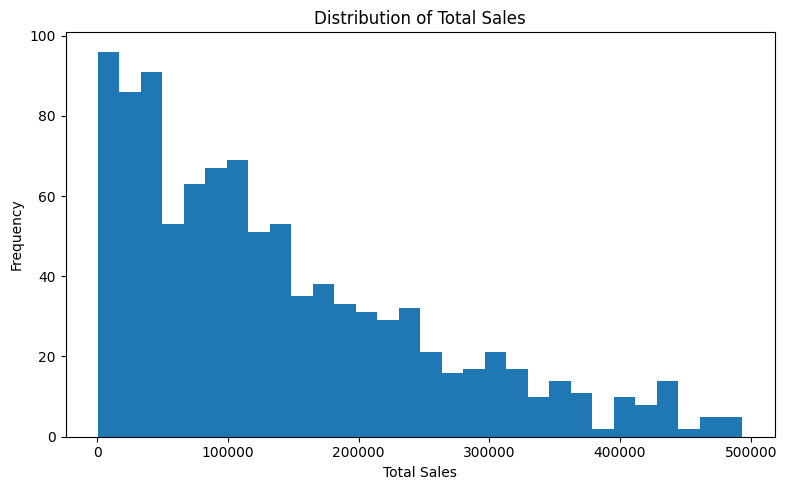

In [11]:

plt.figure(figsize=(8, 5))
plt.hist(df["Total_Sales"].dropna(), bins=30)
plt.title("Distribution of Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


Category
Electronics    50778581.70
Education      25031689.40
Grocery        22231711.28
Furniture      21521561.48
Fashion        19835895.79
Name: Total_Sales, dtype: float64


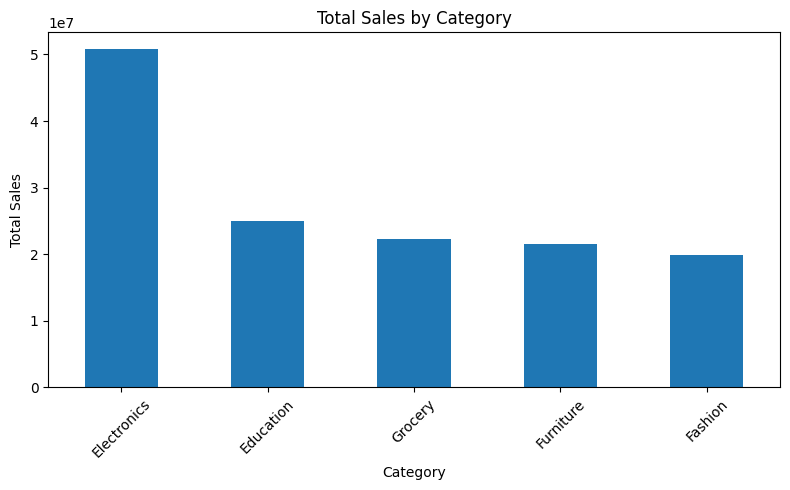

In [12]:

category_sales = (
    df.groupby("Category")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

print(category_sales)

category_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Product
Laptop    25443008.51
Mobile    25335573.19
Book      25031689.40
Rice      22231711.28
Chair     21521561.48
Shoes     19835895.79
Name: Total_Sales, dtype: float64


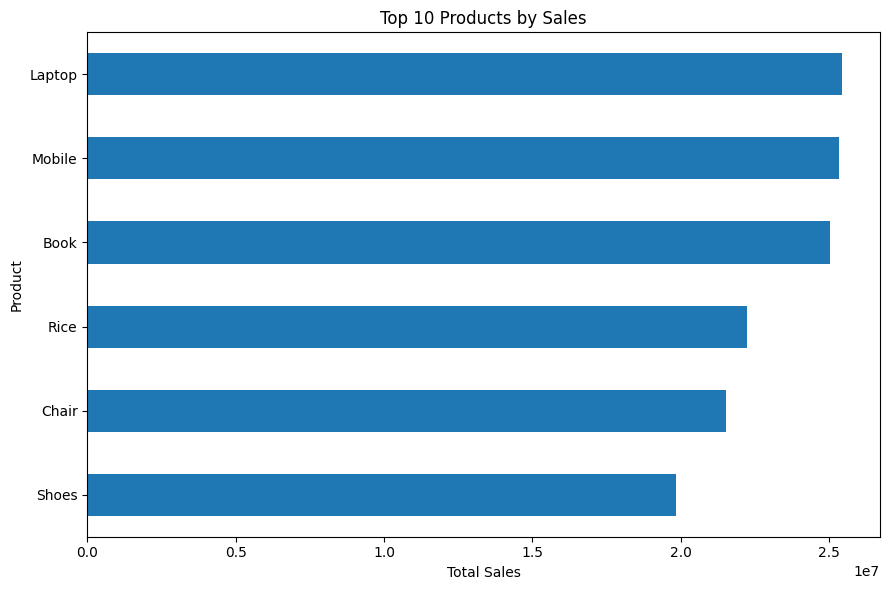

In [13]:

top_products = (
    df.groupby("Product")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

top_products.sort_values().plot(
    kind="barh", figsize=(9, 6)
)
plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


Sales_Month
2025-01    10096190.73
2025-02    11511181.46
2025-03    13059899.94
2025-04    12222700.17
2025-05    10984689.25
2025-06    12912332.64
2025-07    11746226.80
2025-08     9448471.22
2025-09     9179896.29
2025-10    12500936.50
2025-11    12627620.22
2025-12    12299904.44
2026-01      809389.99
Name: Total_Sales, dtype: float64


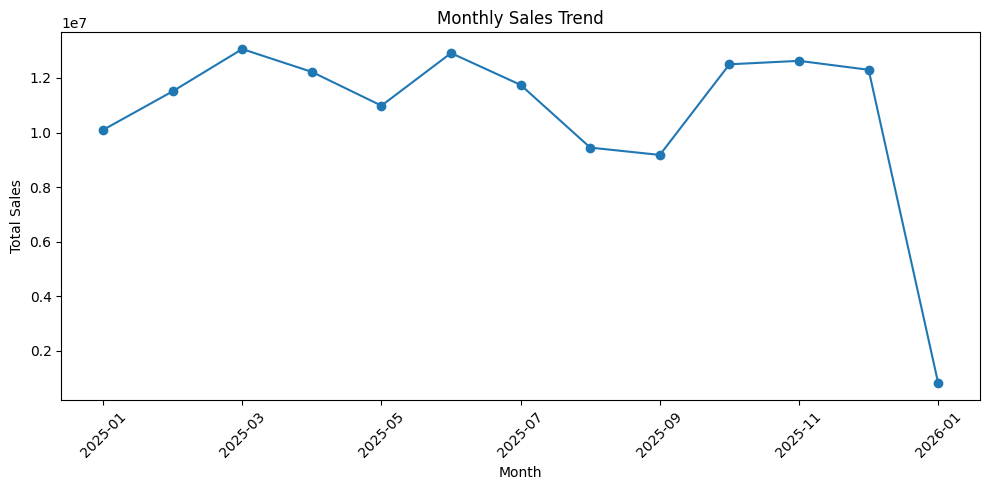

In [14]:

monthly_sales = (
    df.groupby("Sales_Month")["Total_Sales"]
    .sum()
    .sort_index()
)

print(monthly_sales)

monthly_sales.plot(
    kind="line", marker="o", figsize=(10, 5)
)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


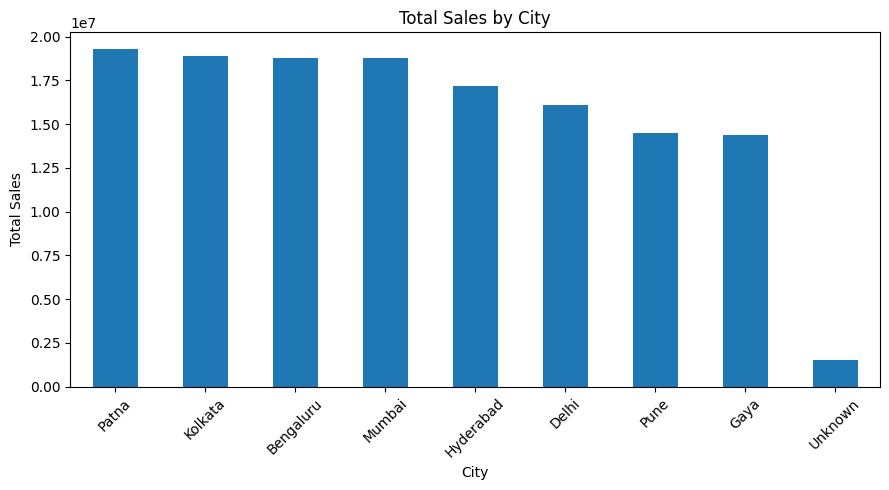

Sales by gender:
Gender
Female    66935889.02
Male      72463550.63
Name: Total_Sales, dtype: float64


In [15]:

city_sales = (
    df.groupby("City")["Total_Sales"]
    .sum()
    .sort_values(ascending=False)
)

city_sales.plot(kind="bar", figsize=(9, 5))
plt.title("Total Sales by City")
plt.xlabel("City")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

gender_sales = df.groupby("Gender")["Total_Sales"].sum()
print("Sales by gender:")
print(gender_sales)


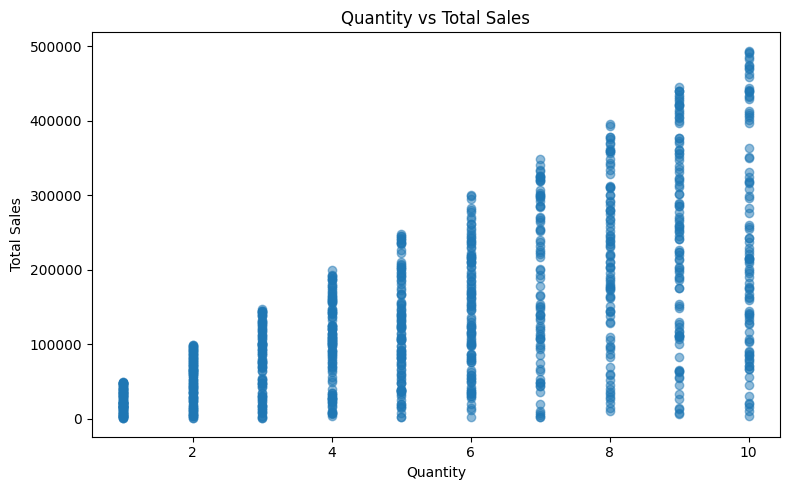

In [16]:

plt.figure(figsize=(8, 5))
plt.scatter(df["Quantity"], df["Total_Sales"], alpha=0.5)
plt.title("Quantity vs Total Sales")
plt.xlabel("Quantity")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()


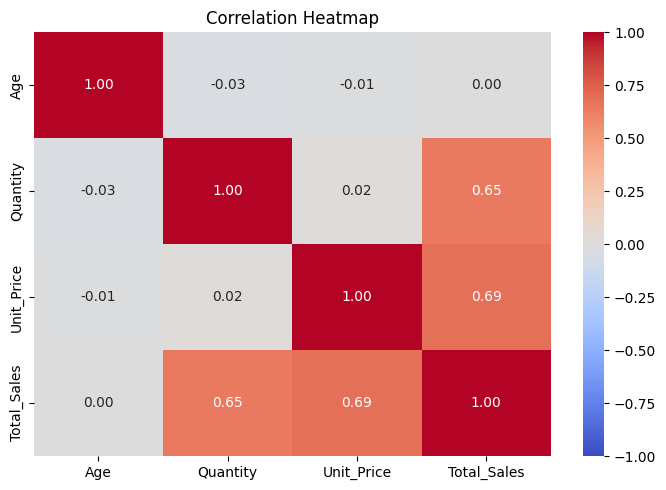

In [17]:

numeric_df = df[
    ["Age", "Quantity", "Unit_Price", "Total_Sales"]
]

correlation = numeric_df.corr()

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


In [18]:
plt.savefig("sales_by_category.png", dpi=300, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>